In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import pandas as pd
from datetime import datetime, date

In [2]:
# Choose a variable:

ds = xr.load_dataset("../Part1_analysis/ERA5_features/grib_files/z500_50_87.grib", engine="cfgrib")
var_daily1 = ds.z.groupby(ds.z.time.dt.date).mean()

Ignoring index file '../Part1_analysis/ERA5_features/grib_files/z500_50_87.grib.5b7b6.idx' incompatible with GRIB file


In [3]:
# Choose a variable:

ds = xr.load_dataset("../Part1_analysis/ERA5_features/grib_files/z500_88_25.grib", engine="cfgrib")
var_daily2 = ds.z.groupby(ds.z.time.dt.date).mean()

Ignoring index file '../Part1_analysis/ERA5_features/grib_files/z500_88_25.grib.5b7b6.idx' incompatible with GRIB file


In [4]:
var_daily = xr.concat([var_daily1, var_daily2], dim='date')

In [5]:
dates = var_daily.date.data
datetimes = np.zeros_like(dates)
for i in range(len(dates)):
    datetimes[i] = datetime.combine(dates[i], datetime.min.time())

In [6]:
var_daily.coords["time"] = ("date", datetimes)
var_daily = var_daily.swap_dims({"date": "time"})
var_daily = var_daily.reset_coords('date', drop=True)

In [7]:
var_daily = var_daily.reset_coords(['number', 'step', 'isobaricInhPa'], drop=True)
var_daily = var_daily.sel(time=slice("1950-07", "2025-06"))
month = var_daily.time.dt.month
day = var_daily.time.dt.day
var_daily = var_daily.sel(time=~((month == 2) & (day == 29)))
var_daily = var_daily.assign_coords({'month_day': 31*var_daily['time.month'] + var_daily['time.day']})

In [8]:
var_7dMean = var_daily.rolling(time=7, min_periods=7, center=True).mean()
month = var_7dMean.time.dt.month
day = var_7dMean.time.dt.day
var_7dMean = var_7dMean.sel(time=~( ((month==10)&(day<4)) | ((month==2)&(day>25)) ))

In [9]:
weights = np.cos(np.deg2rad(var_daily.latitude))
weights.name = "weights"

In [10]:
var_7dMean_regmean = var_7dMean.weighted(weights).mean(dim=['longitude', 'latitude'])
var_7dMean_regstd = var_7dMean.weighted(weights).std(dim=['longitude', 'latitude'])
var_7dMean_regmin = var_7dMean.min(dim=['longitude', 'latitude'])
var_7dMean_regmax = var_7dMean.max(dim=['longitude', 'latitude'])

In [11]:
var_seasonmean_regmean = var_7dMean_regmean.coarsen(time=145).construct(time=("year", "date")).mean(dim='date')
var_seasonmean_regstd = var_7dMean_regstd.coarsen(time=145).construct(time=("year", "date")).mean(dim='date')
var_seasonmean_regmin = var_7dMean_regmin.coarsen(time=145).construct(time=("year", "date")).mean(dim='date')
var_seasonmean_regmax = var_7dMean_regmax.coarsen(time=145).construct(time=("year", "date")).mean(dim='date')

<Axes: >

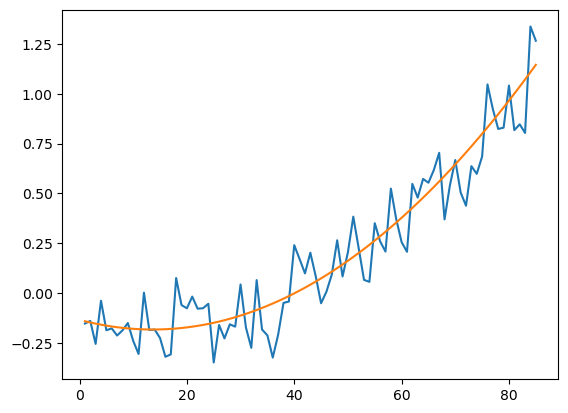

In [12]:
# For temperature & geopotential:

df_gmst = pd.read_csv('../Part1_analysis/era5-0p5deg_world_t2_surface_anom_1951-2000_table.csv', delimiter=',', skiprows=8, usecols=(0,10,11,14))
df_gmst['ONDJF'] = 0.0
df_gmst.loc[1:, 'ONDJF'] = 90/151*df_gmst['DJF'][1:].values + 31/151*df_gmst['Oct'][:-1].values + 30/151*df_gmst['Nov'][:-1].values
df_gmst = df_gmst.drop(index=0)
fit_par = np.polyfit(df_gmst[:70]['Year'], df_gmst[:70]['ONDJF'], 2)
df_gmst['quadr_fit'] = np.polyval(fit_par, df_gmst['Year'])

df_gmst['ONDJF'][:-1].plot()
df_gmst['quadr_fit'][:-1].plot()

In [13]:
# For temperature & geopotential:

fit_par = np.polyfit(df_gmst[10:70]['quadr_fit'], var_seasonmean_regmean[:60], 1)
var_seasonmean_regmean_gws = np.polyval(fit_par, df_gmst[10:-1]['quadr_fit'])

fit_par = np.polyfit(df_gmst[10:70]['quadr_fit'], var_seasonmean_regmax[:60], 1)
var_seasonmean_regmax_gws = np.polyval(fit_par, df_gmst[10:-1]['quadr_fit'])

fit_par = np.polyfit(df_gmst[10:70]['quadr_fit'], var_seasonmean_regmin[:60], 1)
var_seasonmean_regmin_gws = np.polyval(fit_par, df_gmst[10:-1]['quadr_fit'])

0.6932893670544665


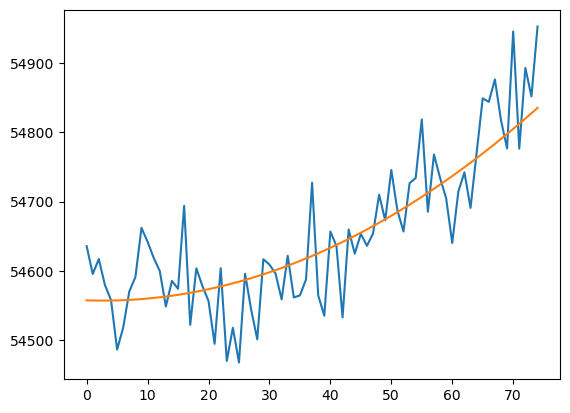

In [14]:
plt.plot(var_seasonmean_regmean.year, var_seasonmean_regmean)
plt.plot(var_seasonmean_regmean.year, var_seasonmean_regmean_gws)
print(np.corrcoef(var_seasonmean_regmean_gws[:60], var_seasonmean_regmean[:60])[0,1])

0.7026198592788416


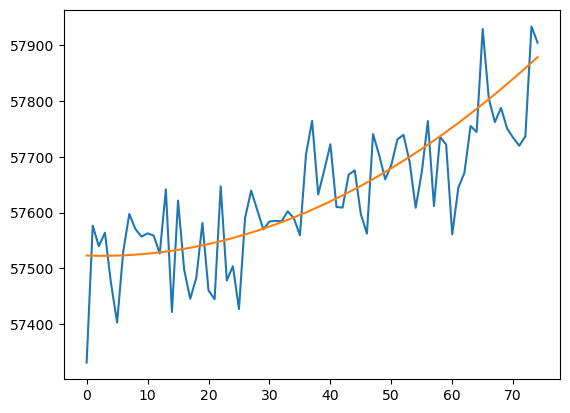

In [15]:
plt.plot(var_seasonmean_regmax.year, var_seasonmean_regmax)
plt.plot(var_seasonmean_regmax.year, var_seasonmean_regmax_gws)
print(np.corrcoef(var_seasonmean_regmax_gws[:60], var_seasonmean_regmax[:60])[0,1])

0.19936065928924182


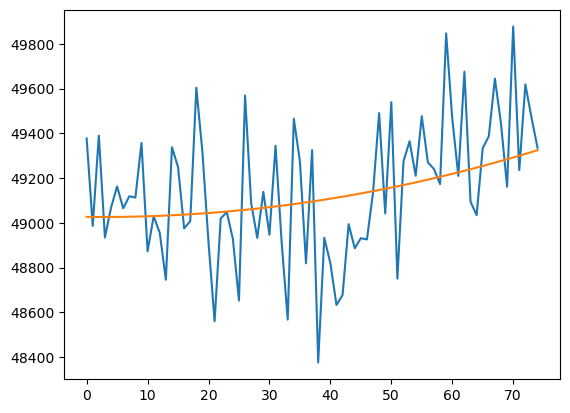

In [16]:
plt.plot(var_seasonmean_regmin.year, var_seasonmean_regmin)
plt.plot(var_seasonmean_regmin.year, var_seasonmean_regmin_gws)
print(np.corrcoef(var_seasonmean_regmin_gws[:60], var_seasonmean_regmin[:60])[0,1])

In [17]:
var_7dMean_regmean_detr = var_7dMean_regmean.coarsen(time=145).construct(time=("year", "date")) - var_seasonmean_regmean_gws[:, np.newaxis]
var_7dMean_regmean_detr = var_7dMean_regmean_detr.stack(day=("year", "date")).swap_dims({"day": "time"}).reset_coords(('day','year','date'), drop=True)

var_7dMean_regstd_detr = var_7dMean_regstd

var_7dMean_regmin_detr = var_7dMean_regmin.coarsen(time=145).construct(time=("year", "date")) - var_seasonmean_regmin_gws[:, np.newaxis]
var_7dMean_regmin_detr = var_7dMean_regmin_detr.stack(day=("year", "date")).swap_dims({"day": "time"}).reset_coords(('day','year','date'), drop=True)

var_7dMean_regmax_detr = var_7dMean_regmax.coarsen(time=145).construct(time=("year", "date")) - var_seasonmean_regmax_gws[:, np.newaxis]
var_7dMean_regmax_detr = var_7dMean_regmax_detr.stack(day=("year", "date")).swap_dims({"day": "time"}).reset_coords(('day','year','date'), drop=True)

In [18]:
var_7dMean_regmean_detr_anom = var_7dMean_regmean_detr.groupby('month_day') - var_7dMean_regmean_detr.sel(time=slice("1950-07", "2010-06")).groupby('month_day').mean()
var_7dMean_regstd_detr_anom = var_7dMean_regstd_detr.groupby('month_day') - var_7dMean_regstd_detr.sel(time=slice("1950-07", "2010-06")).groupby('month_day').mean()
var_7dMean_regmin_detr_anom = var_7dMean_regmin_detr.groupby('month_day') - var_7dMean_regmin_detr.sel(time=slice("1950-07", "2010-06")).groupby('month_day').mean()
var_7dMean_regmax_detr_anom = var_7dMean_regmax_detr.groupby('month_day') - var_7dMean_regmax_detr.sel(time=slice("1950-07", "2010-06")).groupby('month_day').mean()

In [19]:
# Choose appropriate names:

df_var = var_7dMean_regmean_detr_anom.to_dataframe(name='z500_mean')
df_var['z500_std'] = var_7dMean_regstd_detr_anom.to_dataframe()['z']
df_var['z500_min'] = var_7dMean_regmin_detr_anom.to_dataframe()['z']
df_var['z500_max'] = var_7dMean_regmax_detr_anom.to_dataframe()['z']

In [20]:
df_var = df_var.drop(['month_day'], axis=1)
month = df_var.index.month
day = df_var.index.day
df_var_week3 = df_var[((month == 11) & (day >= 13)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 4))]
df_var_week4 = df_var[((month == 11) & (day >= 6)) | (month == 12) | ((month == 1) & (day <= 28))]

In [21]:
df_var_week3

,z500_mean,z500_std,z500_min,z500_max
time,,,,
1950-11-13,-32.740009,116.534529,113.553932,-175.163857
1950-11-14,-52.177360,116.603128,139.584596,-237.593349
1950-11-15,-51.483421,81.323899,250.231146,-278.459495
1950-11-16,-20.132418,1.933251,537.680820,-311.559365
1950-11-17,22.337705,-110.957451,857.994231,-336.192894
...,...,...,...,...
2025-01-31,307.887821,142.350598,-1023.829284,292.759127
2025-02-01,308.567926,137.335500,-1086.147839,182.600989
2025-02-02,290.676961,161.918720,-1192.985469,61.615052


<Axes: xlabel='time'>

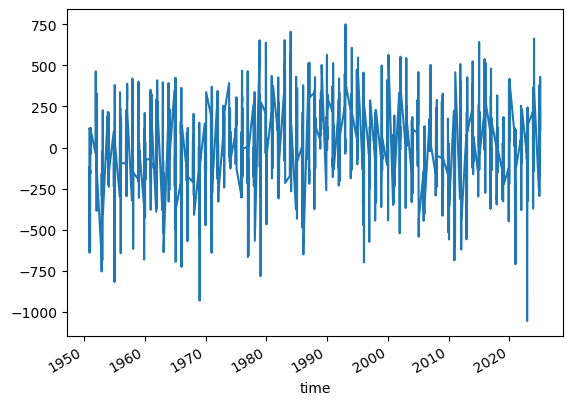

In [23]:
df_var_week3['z500_std'].plot()

In [24]:
# Name files appropriately:

df_var_week3.to_csv('z500_week3.csv')
df_var_week4.to_csv('z500_week4.csv')